# Weekly project part 1
Using the image "appletree.jpg"
1) Can you segment the apples from the tree?
2) Can you get the computer to count how many there are? 
    How close can you get to the ground truth? (there are 26 apples in the image)
3) Can you change the color of one of them?
4) Can you segment the leaves?

In [1]:
import cv2
import numpy as np
import imutils
from matplotlib import pyplot as plt

## 1) Segmenting the apples from the tree
The apples are the only strongly red/pink objects in the image, so we can segment them with a color threshold in HSV space. Red wraps around hue $0$ in OpenCV's $0$-$179$ hue range, so we combine a low-hue and a high-hue range into a single mask, then clean it up with morphological opening (removes small speckles) and closing (fills small holes).

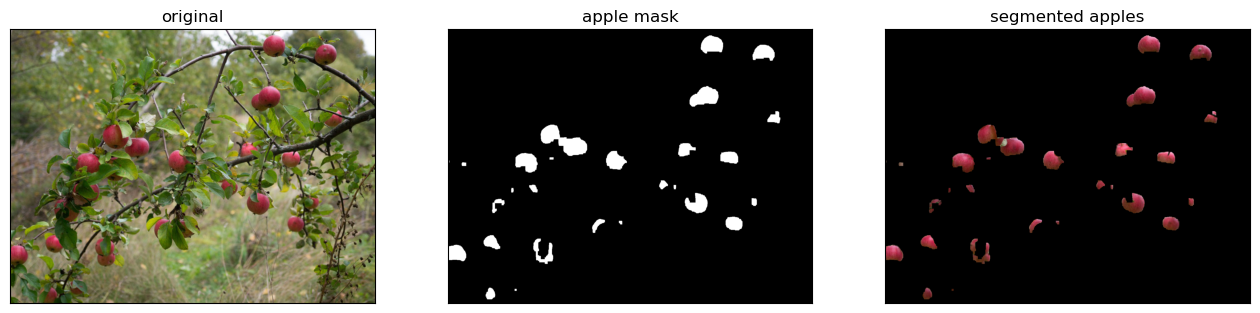

In [2]:
bgr_img = cv2.imread("appletree.jpg")
b, g, r = cv2.split(bgr_img)
image = cv2.merge([r, g, b])

hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

# red wraps around hue=0 on OpenCV's 0-179 hue scale, so we need two ranges
lower_red_1, upper_red_1 = np.array([0, 60, 40]), np.array([12, 255, 255])
lower_red_2, upper_red_2 = np.array([160, 60, 40]), np.array([179, 255, 255])

apple_mask = cv2.bitwise_or(
    cv2.inRange(hsv, lower_red_1, upper_red_1),
    cv2.inRange(hsv, lower_red_2, upper_red_2),
)

# clean up the mask: remove small speckles, then close small gaps/holes
apple_mask = cv2.morphologyEx(apple_mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8), iterations=2)
apple_mask = cv2.morphologyEx(apple_mask, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8), iterations=2)

apples_only = cv2.bitwise_and(image, image, mask=apple_mask)

plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1), plt.imshow(image), plt.title("original"), plt.xticks([]), plt.yticks([])
plt.subplot(1, 3, 2), plt.imshow(apple_mask, cmap="gray"), plt.title("apple mask"), plt.xticks([]), plt.yticks([])
plt.subplot(1, 3, 3), plt.imshow(apples_only), plt.title("segmented apples"), plt.xticks([]), plt.yticks([])
plt.show()

## 2) Counting the apples
We find the contours of the mask and keep only the ones large enough to plausibly be an apple, which discards tiny leftover speckles. Ground truth is 26 apples.

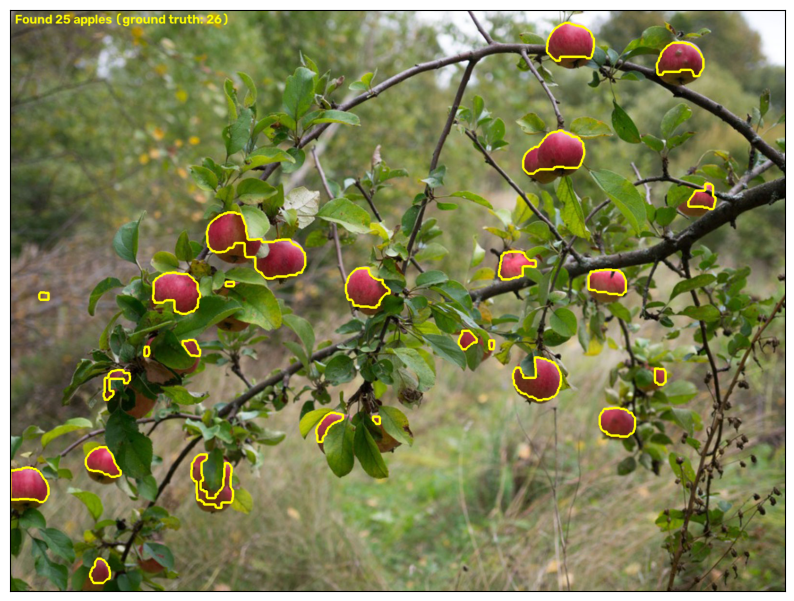

Found 25 apples (ground truth: 26)


In [3]:
cnts = cv2.findContours(apple_mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = imutils.grab_contours(cnts)

min_area = 100  # discard tiny speckles that aren't real apples
apple_cnts = [c for c in cnts if cv2.contourArea(c) > min_area]

output = image.copy()
for c in apple_cnts:
    cv2.drawContours(output, [c], -1, (255, 255, 0), 3)

text = "Found {} apples (ground truth: 26)".format(len(apple_cnts))
cv2.putText(output, text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(output)
plt.xticks([]), plt.yticks([])
plt.show()

print(text)

Lowering `min_area` from 400 to 100 raises the count from 20 to 25 out of 26, since it lets through smaller red slivers of apples that are mostly hidden behind leaves. We stop at 100 rather than going lower: below that, the remaining "apples" gained are mostly reddish speckles in the blurred background (dead leaves, twigs) rather than real apples. Pushing `min_area` down to e.g. 50 does hit exactly 26, but only because a couple of background false positives happen to cancel out a couple of still-missed real apples, not because every apple is now correctly found. The remaining gap comes from two limitations of simple color thresholding: (1) apples that are almost entirely hidden behind leaves, where no red sliver survives the mask at all, and (2) apples that are touching each other and get merged into a single contour.

## 3) Changing the color of one apple
We pick one of the detected apple contours, build a mask for just that single apple, and shift its hue in HSV space (leaving saturation and value untouched) so it turns green while keeping its shading and texture.

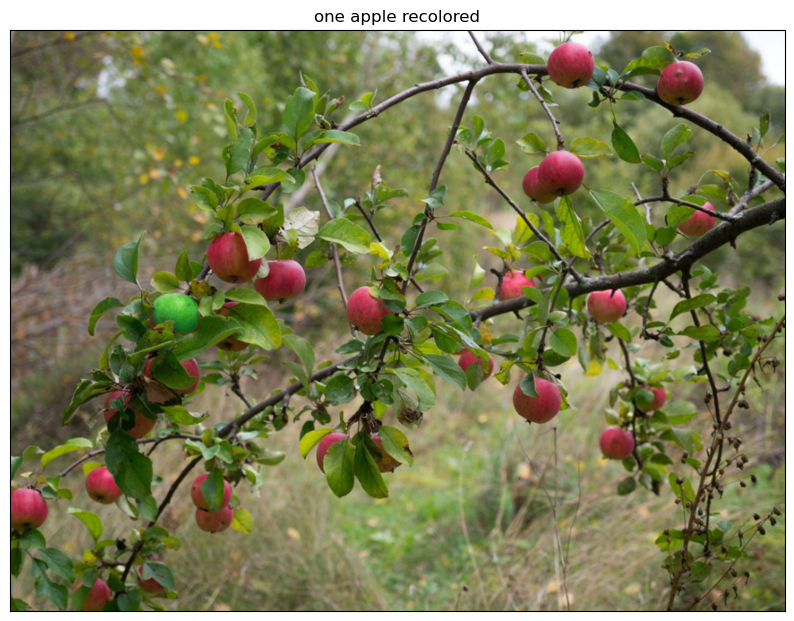

In [4]:
apple_cnts_sorted = sorted(apple_cnts, key=cv2.contourArea, reverse=True)
chosen_apple = apple_cnts_sorted[2]  # pick one clean, single-apple blob

single_apple_mask = np.zeros(apple_mask.shape, dtype=np.uint8)
cv2.drawContours(single_apple_mask, [chosen_apple], -1, 255, -1)

recolored_hsv = hsv.copy().astype(np.int32)
hue_shift = 60  # red -> green
recolored_hsv[:, :, 0] = np.where(
    single_apple_mask == 255,
    (recolored_hsv[:, :, 0] + hue_shift) % 180,
    recolored_hsv[:, :, 0],
)
recolored = cv2.cvtColor(recolored_hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(recolored)
plt.title("one apple recolored")
plt.xticks([]), plt.yticks([])
plt.show()

## 4) Segmenting the leaves
Leaves are green, so the same color-thresholding approach works, this time on the green part of the hue range.

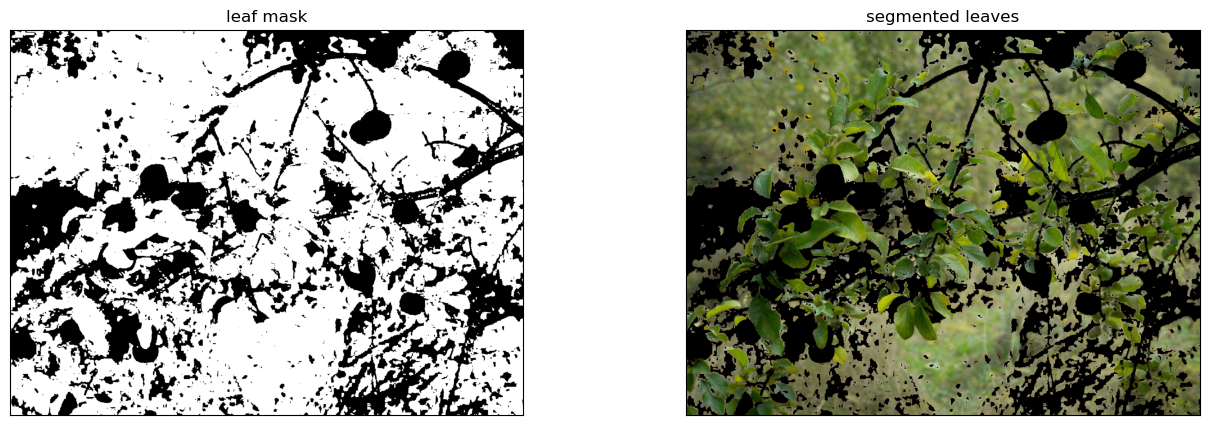

In [5]:
lower_green, upper_green = np.array([25, 40, 30]), np.array([95, 255, 255])
leaf_mask = cv2.inRange(hsv, lower_green, upper_green)
leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8), iterations=1)

leaves_only = cv2.bitwise_and(image, image, mask=leaf_mask)

plt.figure(figsize=(16, 5))
plt.subplot(1, 2, 1), plt.imshow(leaf_mask, cmap="gray"), plt.title("leaf mask"), plt.xticks([]), plt.yticks([])
plt.subplot(1, 2, 2), plt.imshow(leaves_only), plt.title("segmented leaves"), plt.xticks([]), plt.yticks([])
plt.show()

Note: the blurred background also contains a lot of green (grass, out-of-focus trees), so this mask segments "green pixels" rather than "leaves of this tree" specifically. Separating those would need more than color, e.g. sharpness/blur or depth information.

# Weekly project part 2
1) Remove the greenscreen and replace the background in "itssp.png".
2) Can you improve the edge with eroding/dilating?